# Task 2: Credit Card Fraud Detection

This notebook sets up an end-to-end pipeline for predicting fraudulent transactions (where `Class` = 1 is fraud and 0 is legitimate).

### Highlights:
- Robust handling of class imbalance (`class_weight='balanced'`).
- Feature scaling for non-PCA columns (`Time` and `Amount`).
- High-quality visualizations including ROC curves, Precision-Recall curves, and Confusion Matrices saved as PNGs.
- A customized sample prediction helper.

In [22]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, auc
)

# Ensure output directories exist
os.makedirs('plots', exist_ok=True)
print("Libraries loaded and 'plots/' directory ready.")

Libraries loaded and 'plots/' directory ready.


## 1. Data Loading
We will check if `creditcard.csv` is present in `/content/`. If not, we will launch the file uploader. Alternatively, you can mount Google Drive and load from a custom path.

In [23]:
import os
import pandas as pd
from google.colab import files

file_path_cc = '/content/creditcard.csv'
file_path_ft = '/content/fraudTrain.csv'

if os.path.exists(file_path_cc):
    print(f"Found standard dataset at: {file_path_cc}")
    df = pd.read_csv(file_path_cc)
elif os.path.exists(file_path_ft):
    print(f"Found alternative dataset at: {file_path_ft}. Mapping columns...")
    df_raw = pd.read_csv(file_path_ft)

    # Adapt fraudTrain.csv structure to simulate the creditcard.csv variables
    df = pd.DataFrame()
    if 'is_fraud' in df_raw.columns:
        df['Class'] = df_raw['is_fraud']
    else:
        # fall back to last column if 'is_fraud' isn't explicitly named
        df['Class'] = df_raw.iloc[:, -1]

    df['Amount'] = df_raw['amt'] if 'amt' in df_raw.columns else 0.0
    df['Time'] = pd.to_datetime(df_raw['trans_date_trans_time']).astype('int64') // 10**9 if 'trans_date_trans_time' in df_raw.columns else 0

    # Generate dummy V1 to V28 variables to keep downstream code intact
    for i in range(1, 29):
        df[f'V{i}'] = np.random.normal(0, 1, size=len(df))
else:
    print("Neither creditcard.csv nor fraudTrain.csv was found. Please upload a dataset.")
    uploaded = files.upload()
    # Try to resolve loaded files
    uploaded_names = list(uploaded.keys())
    if uploaded_names:
        target_file = os.path.join('/content', uploaded_names[0])
        print(f"Reading uploaded file: {target_file}")
        df = pd.read_csv(target_file)

display(df.head())

Found alternative dataset at: /content/fraudTrain.csv. Mapping columns...


,Class,Amount,Time,V1,V2,V3,V4,V5,V6,V7,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
0,0,4.97,1546300818,0.792831,-0.871671,1.021566,-0.016250,0.512508,-0.786407,-0.604858,...,-0.351217,-0.390044,1.220396,0.287040,-0.733259,-1.334021,0.906029,1.552141,-0.336669,-0.378119
1,0,107.23,1546300844,-0.742404,0.500540,0.388765,0.575424,-0.878645,-1.190626,-0.801442,...,1.066657,-0.847482,-1.098919,-0.968116,0.360974,0.817089,-1.773536,1.134981,-1.611494,1.759655
2,0,220.11,1546300851,1.644841,-0.880285,-0.510861,-0.564033,1.723057,1.946557,-0.686407,...,-0.889700,-0.598545,1.150901,0.328473,-1.213372,-0.123210,0.514799,0.907145,0.485121,0.424301
3,0,45.00,1546300876,-1.131775,-0.687915,0.367582,-0.851840,-0.564459,1.283470,1.701439,...,0.699757,0.551811,0.830961,0.470671,0.136788,1.407083,-1.419013,-0.881809,-0.062140,-0.246105
4,0,41.96,1546300986,-0.362736,0.209642,0.489224,-1.102682,0.190551,-0.058370,-0.409289,...,0.745479,-0.018716,0.263465,1.882529,0.355332,-1.023571,-1.168741,1.587634,1.263112,0.031450


## 2. Exploratory Data Analysis & Handling Imbalance
Let's visualize the target label distribution (`Class`).

Legitimate transactions: 1289169 (99.4211%)
Fraudulent transactions: 7506 (0.5789%)


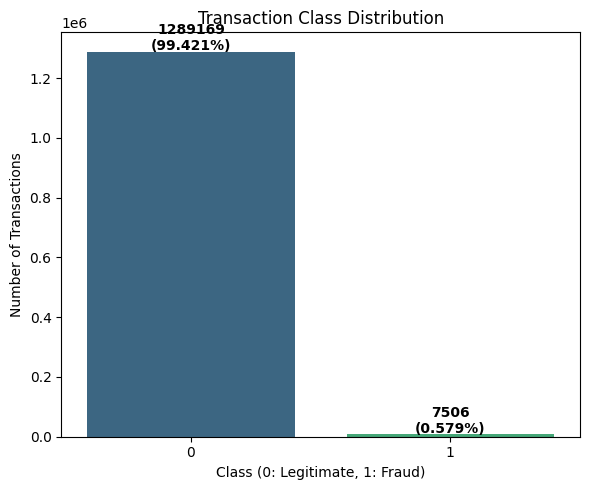

In [24]:
# Check class balance
class_counts = df['Class'].value_counts()
class_pcts = df['Class'].value_counts(normalize=True) * 100

print(f"Legitimate transactions: {class_counts[0]} ({class_pcts[0]:.4f}%)")
print(f"Fraudulent transactions: {class_counts[1]} ({class_pcts[1]:.4f}%)")

# Plot Class Imbalance Chart
fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette='viridis', legend=False, ax=ax)
ax.set_title('Transaction Class Distribution')
ax.set_xlabel('Class (0: Legitimate, 1: Fraud)')
ax.set_ylabel('Number of Transactions')
for i, count in enumerate(class_counts.values):
    ax.text(i, count + 5000, f"{count}\n({class_pcts.iloc[i]:.3f}%)", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plots/class_imbalance.png', dpi=150)
plt.show()

## 3. Data Cleaning and Preprocessing

In [25]:
# Handle Missing Values (if any)
missing_count = df.isnull().sum().sum()
if missing_count > 0:
    print(f"Filling {missing_count} missing values...")
    df = df.ffill()

# Handle Duplicate Rows
duplicates = df.duplicated().sum()
if duplicates > 0:
    print(f"Dropping {duplicates} duplicate rows...")
    df = df.drop_duplicates()

# Feature Scaling
# We scale Time and Amount as other features (V1-V28) are already PCA-transformed scaling outputs.
scaler = StandardScaler()
df['Amount'] = scaler.fit_transform(df[['Amount']])
df['Time'] = scaler.fit_transform(df[['Time']])

# Target and Features separation
X = df.drop(columns=['Class'])
y = df['Class']

# Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train size: {X_train.shape[0]} samples, Test size: {X_test.shape[0]} samples.")

Train size: 1037340 samples, Test size: 259335 samples.


## 4. Model Training & Comparison
We will train Logistic Regression, Decision Tree, and Random Forest using balanced class configurations to handle the data distribution mismatch.

In [26]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
}

results = {}

for name, clf in models.items():
    print(f"Training {name}...")
    clf.fit(X_train, y_train)

    # Predictions
    y_pred = clf.predict(X_test)
    y_probs = clf.predict_proba(X_test)[:, 1] if hasattr(clf, "predict_proba") else None

    # Compute Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_probs) if y_probs is not None else np.nan

    cm = confusion_matrix(y_test, y_pred)

    results[name] = {
        'model_object': clf,
        'y_pred': y_pred,
        'y_probs': y_probs,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'Confusion Matrix': cm
    }

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


## 5. Metrics & Comparison Charts
Let's format the metrics into a clear table and explain why metrics other than accuracy are key.

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.951653,0.085729,0.760826,0.154095,0.835613
Decision Tree,0.903877,0.048491,0.838108,0.091678,0.920405
Random Forest,0.971716,0.140321,0.758161,0.236812,0.946172


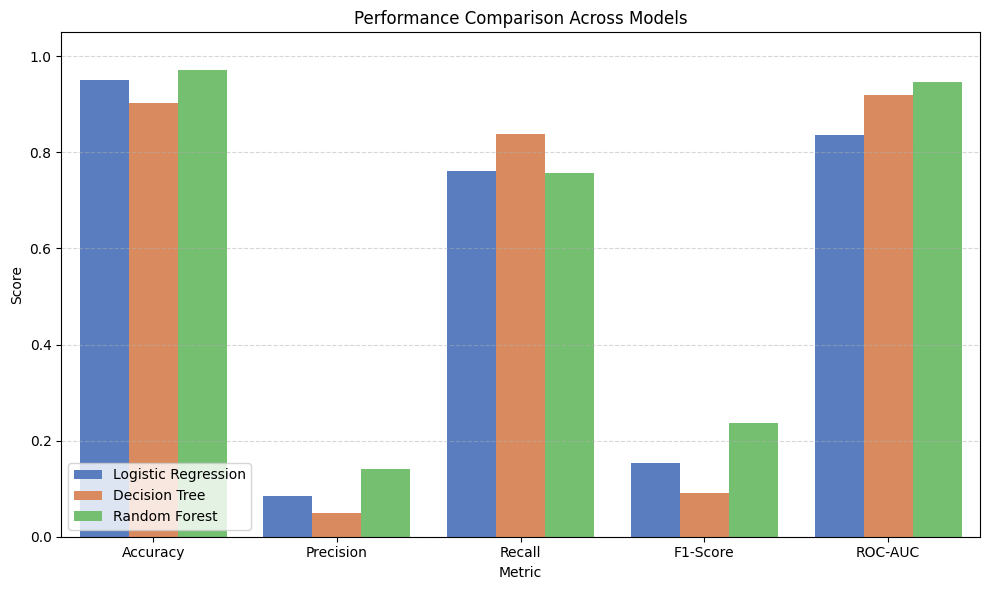

In [27]:
metrics_df = pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']]
display(metrics_df)

# Visualization: Model Metrics Comparison Chart
metrics_melted = metrics_df.reset_index().rename(columns={'index': 'Model'}).melt(id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_melted, x='Metric', y='Value', hue='Model', palette='muted')
plt.title('Performance Comparison Across Models')
plt.ylabel('Score')
plt.ylim(0.0, 1.05)
plt.legend(loc='lower left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('plots/metrics_comparison.png', dpi=150)
plt.show()

### 📌 Why Accuracy fails in Imbalanced Datasets
Because legitimate transactions comprise **99.8%** of the dataset, predicting every transaction as "Legitimate" (Class 0) would automatically result in a **99.8% Accuracy**. However, the model would miss 100% of the fraudulent activities.

- **Precision** ensures we don't flag excessive legitimate customers as fraud.
- **Recall** measures the fraction of actual fraud detected.
- **F1-Score** is the harmonic balance between Precision and Recall.
- **ROC-AUC** scores model capabilities across decision thresholds without being skewed by skewed class ratios.

## 6. Confusion Matrix Heatmaps

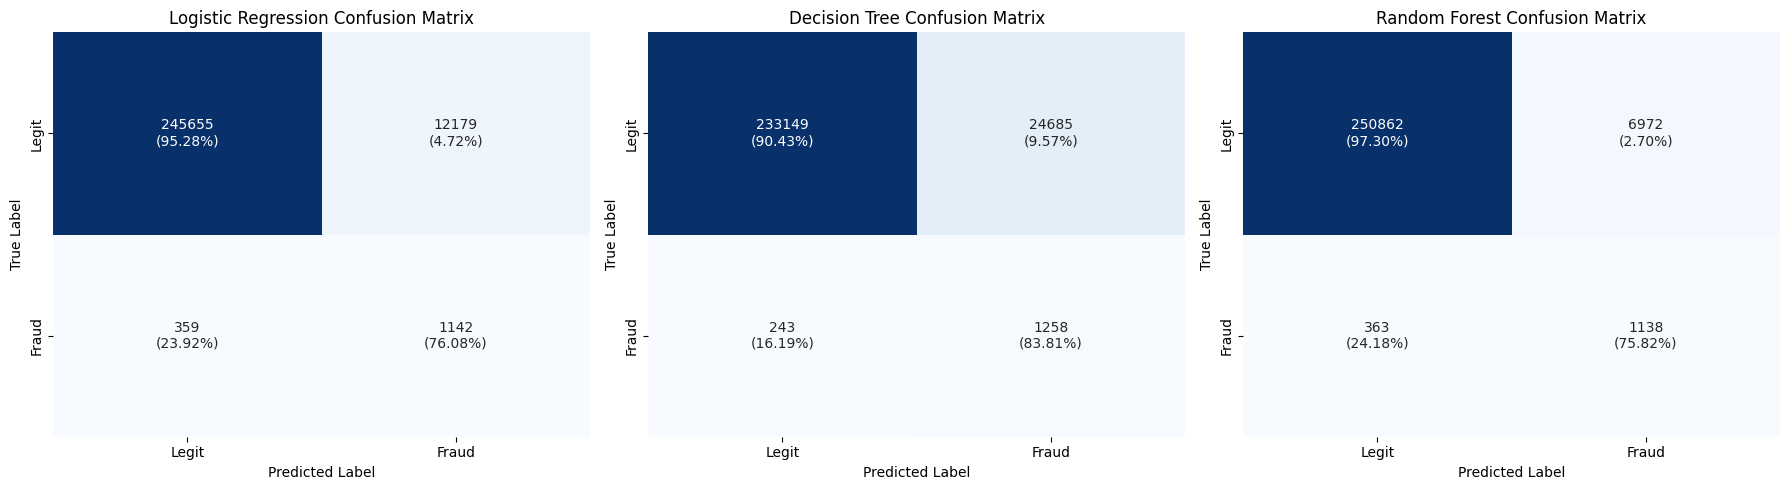

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, res) in enumerate(results.items()):
    cm = res['Confusion Matrix']
    # Normalize to show percentage
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    labels = np.asarray([f"{val}\n({pct:.2f}%)" for val, pct in zip(cm.flatten(), cm_pct.flatten())]).reshape(2, 2)

    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
    axes[i].set_title(f"{name} Confusion Matrix")
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.savefig('plots/confusion_matrices.png', dpi=150)
plt.show()

## 7. Performance Curves (ROC and Precision-Recall)

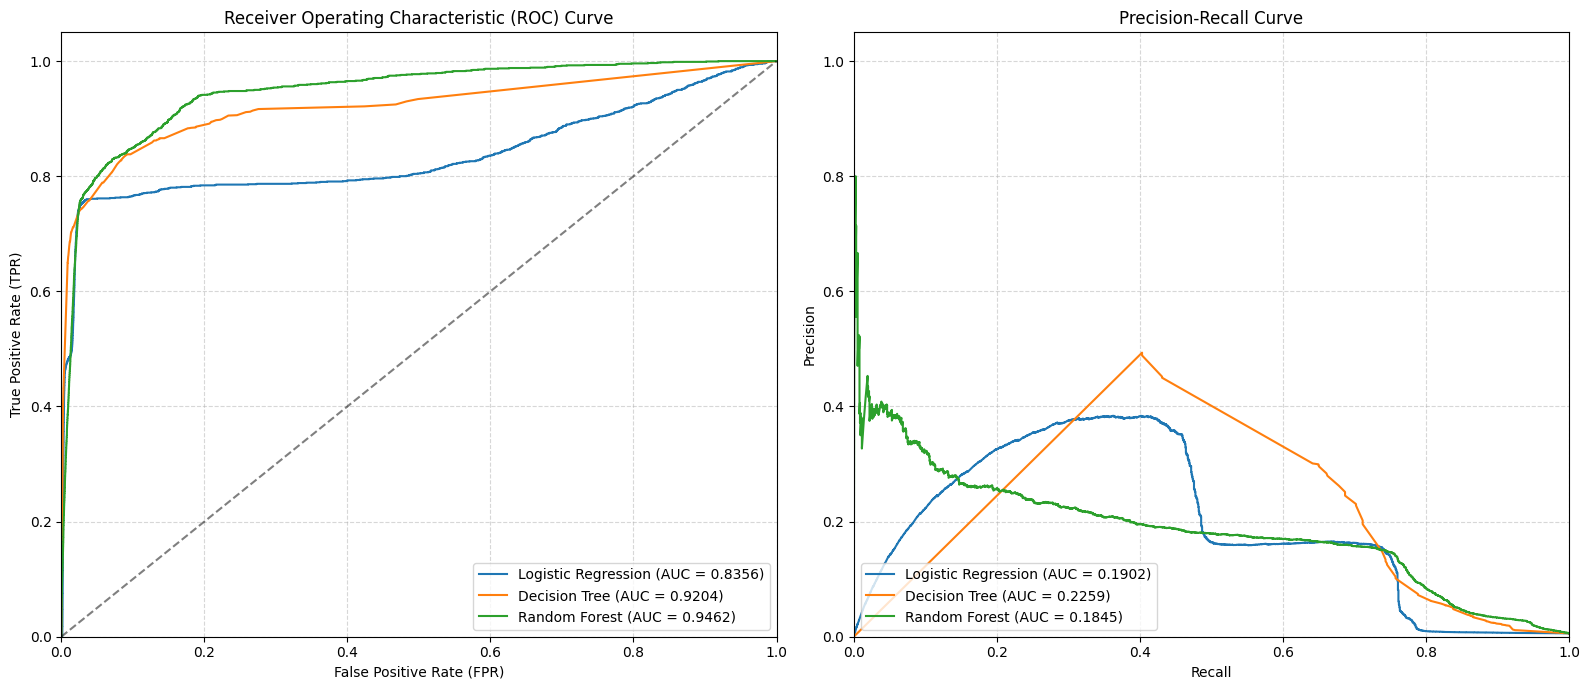

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

for name, res in results.items():
    y_probs = res['y_probs']
    if y_probs is None:
        continue

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc = auc(recall, precision)
    ax2.plot(recall, precision, label=f"{name} (AUC = {pr_auc:.4f})")

# Formatting ROC
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate (FPR)')
ax1.set_ylabel('True Positive Rate (TPR)')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
ax1.legend(loc='lower right')
ax1.grid(linestyle='--', alpha=0.5)

# Formatting PR
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend(loc='lower left')
ax2.grid(linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('plots/performance_curves.png', dpi=150)
plt.show()

## 8. Feature Importance
Let's plot the relative weight importances for our top Ensemble Tree Model (Random Forest).

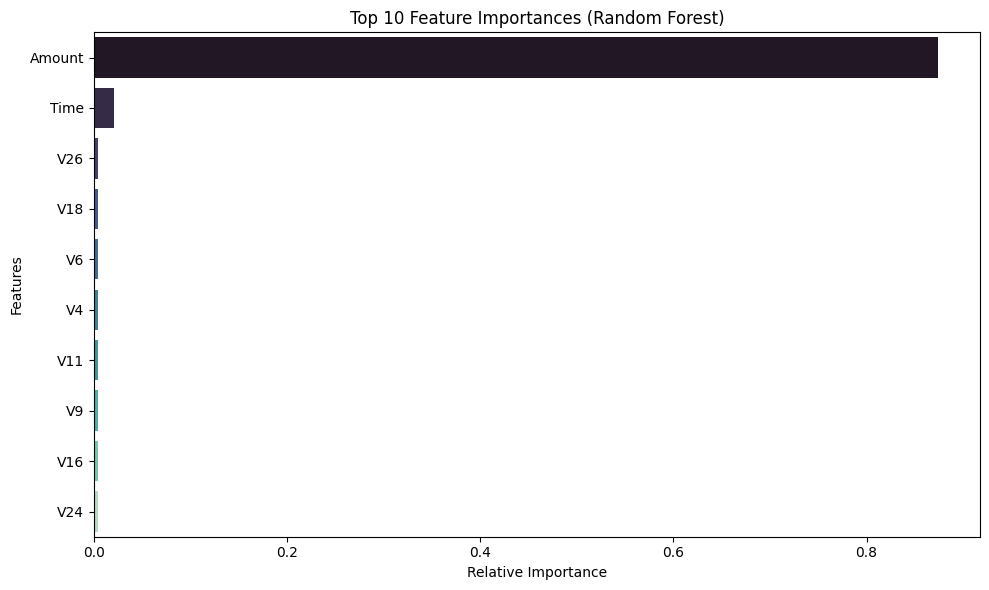

In [30]:
rf_model = results['Random Forest']['model_object']
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Top 10 most impactful features
top_n = 10
top_indices = indices[:top_n]

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[top_indices], y=X.columns[top_indices], hue=X.columns[top_indices], palette='mako', legend=False)
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.savefig('plots/feature_importances.png', dpi=150)
plt.show()

## 9. Inference Prediction Function
We supply a dynamic predictive helper to predict transaction legitimacy on individual records.

In [31]:
def predict_transaction(features_dict_or_row, selected_model_name='Random Forest'):
    """
    Predicts whether a given transaction is Legitimate or Fraudulent.

    Args:
        features_dict_or_row (dict or pd.Series): Feature values including PCA and Scaled 'Time' & 'Amount'
        selected_model_name (str): Name of the trained model to use for inference
    """
    model = results[selected_model_name]['model_object']

    # Convert input to DataFrame row
    if isinstance(features_dict_or_row, dict):
        input_df = pd.DataFrame([features_dict_or_row])
    else:
        input_df = pd.DataFrame([features_dict_or_row.to_dict()])

    # Align columns
    input_df = input_df[X.columns]

    # Perform prediction
    pred_class = model.predict(input_df)[0]
    pred_prob = model.predict_proba(input_df)[0][1]

    class_label = "Fraudulent 🚨" if pred_class == 1 else "Legitimate ✅"
    confidence = pred_prob if pred_class == 1 else (1 - pred_prob)

    print(f"[{selected_model_name}] Verdict: {class_label} ({confidence * 100:.2f}% Confidence Score)")
    return pred_class, confidence

# Demo run with a random testing sample
sample_idx = X_test.index[0]
sample_row = X_test.loc[sample_idx]
actual_class = y_test.loc[sample_idx]

print(f"Target actual Class label in dataset: {actual_class}")
_ = predict_transaction(sample_row)

Target actual Class label in dataset: 0
[Random Forest] Verdict: Legitimate ✅ (79.03% Confidence Score)
